# 06. Потоковое распознавание

**Вопрос этапа:** как модель ведёт себя в непрерывном потоке — сколько жестов дают верную
команду, как часто браслет срабатывает сам, когда рука расслаблена, и с какой задержкой?

Цепочка: **поток сигнала → каузальный фильтр → модель каждые 50 мс → вероятности 17 классов → постобработка →
команды → сравнение с разметкой.**

Эксперименты (`python run.py --config configs/<имя>.yaml`): `stream_dev` — подбор постобработки на 10 dev-участниках,
`stream_test` — один прогон на 5 test-участниках с замороженными настройками. Код: `src/streaming.py`, `run_stream` в
`run.py`. Ноутбук ничего не обучает: вероятности моделей берутся из кэша, результаты — из `results/`.

In [1]:
import sys, json, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

import run
import streaming
from preprocess import design_filter, filter_causal
pd.set_option("display.width", 160)

NAMES = {("lda", "E2"): "своя LDA, новый день", ("lda", "E3"): "своя LDA, новый человек",
         ("tcn", "E2"): "TCN, новый день", ("tcn", "E3"): "TCN, новый человек"}


def load(name: str) -> dict | None:
    # Result file results/<name>.json, or None with a hint if the experiment has not been run yet.
    path = ROOT / "results" / f"{name}.json"
    if not path.exists():
        print(f"Результатов ещё нет: python run.py --config configs/{name}.yaml")
        return None
    return json.loads(path.read_text(encoding="utf-8"))


def point_table(res: dict) -> pd.DataFrame:
    # Event metrics at the operating point: mean ± SD over participants (false activations: mean, median, max).
    at = pd.DataFrame(res["at_operating_point"])
    ops = pd.DataFrame(res["operating_points"]).set_index(["model", "experiment"])
    rows = {}
    for key, g in at.groupby(["model", "experiment"]):
        o = ops.loc[key]
        f = lambda c, k=100: f"{k * g[c].mean():.1f} ± {k * g[c].std():.1f}"
        rows[NAMES[key]] = {
            "сглаж. / мин. длит. / рефракт., мс; порог": f"{o.tau_ms:g} / {o.min_ms:g} / {o.refractory_ms:g}; {o.theta:g}",
            "верные, %": f("correct"), "перепутанные, %": f("confused"), "пропуски, %": f("missed"),
            "лишние на жест": f"{g.extra_per_gesture.mean():.2f}",
            "ложные в мин: среднее (медиана) [макс]":
                f"{g.fa_per_min.mean():.2f} ({g.fa_per_min.median():.2f}) [{g.fa_per_min.max():.1f}]",
            "задержка, мс": f("latency_ms_median", 1)}
    return pd.DataFrame(rows).T

## 1. Зачем потоковые метрики

До сих пор мы мерили **точность по окнам**: каждые 50 мс модель называет жест, считаем долю верных ответов.
Пользователь видит не окна, а **команды**: «сделал жест — сработала нужная команда», «ничего не делал — ничего не случилось».

За минуту модель принимает 1200 решений. Если в покое она ошибается в 1 % окон и ошибки разбросаны поодиночке, каждая
может стать командой — **12 ложных команд в минуту** при точности 99 %. И наоборот, 70 % верных окон подряд дают
надёжную команду. Важно не сколько окон верных, а **как ошибки расположены во времени**.

## 2. Поток

В GRABMyo нет непрерывных записей, поэтому поток **склеивается** из тестовых попыток 4–7 одной сессии
(попытки 1–3 ушли на калибровку моделей, 3 прохода × 1 с, как на этапе 5):

```
покой 3 с | жест 1–2 с | покой 2–4 с | жест 1–2 с | … 64 жеста (16 × 4 попытки), ~4,7 мин
```

- **Жест** — случайный кусок 1–2 с из попытки этого жеста, порядок жестов случайный.
- **Покой** — куски из «запаса покоя»: 4 попытки покоя этой сессии, склеенные в 20 с и прочитанные по кругу.
- **Стыки** — переходы с постоянной мощностью: уходящий кусок × cos, приходящий × sin, cos² + sin² = 1, поэтому
  у двух независимых шумоподобных сигналов мощность на переходе не проваливается. Покой → жест — 50 мс (модель
  разгона сокращения), жест → покой — 50 мс (расслабление), стыки внутри запаса покоя — 20 мс.
- Весь поток фильтруется **каузально, одним проходом**, как в браслете.
- Поток зависит только от (сид, участник, сессия): обе модели и оба сценария оцениваются на **одном и том же** потоке.

**Ограничения:** в попытках нет настоящего начала движения — разгон 50 мс это допущение, и задержка получается
нижней оценкой. Уникального покоя всего 20 с на сессию: куски повторяются.

**Модели** (обе с калибровкой 3 × 1 с из этапа 5):
- **своя LDA** — обучена только на калибровке этой сессии;
- **предобученная TCN** — обучена заранее (новый день: на своей сессии 1; новый человек: на других людях),
  затем AdaBN и дообучение всей сети на калибровке.

Ниже — 30 секунд потока одного dev-участника (11, сессия 2, новый день) в рабочих точках обеих моделей.

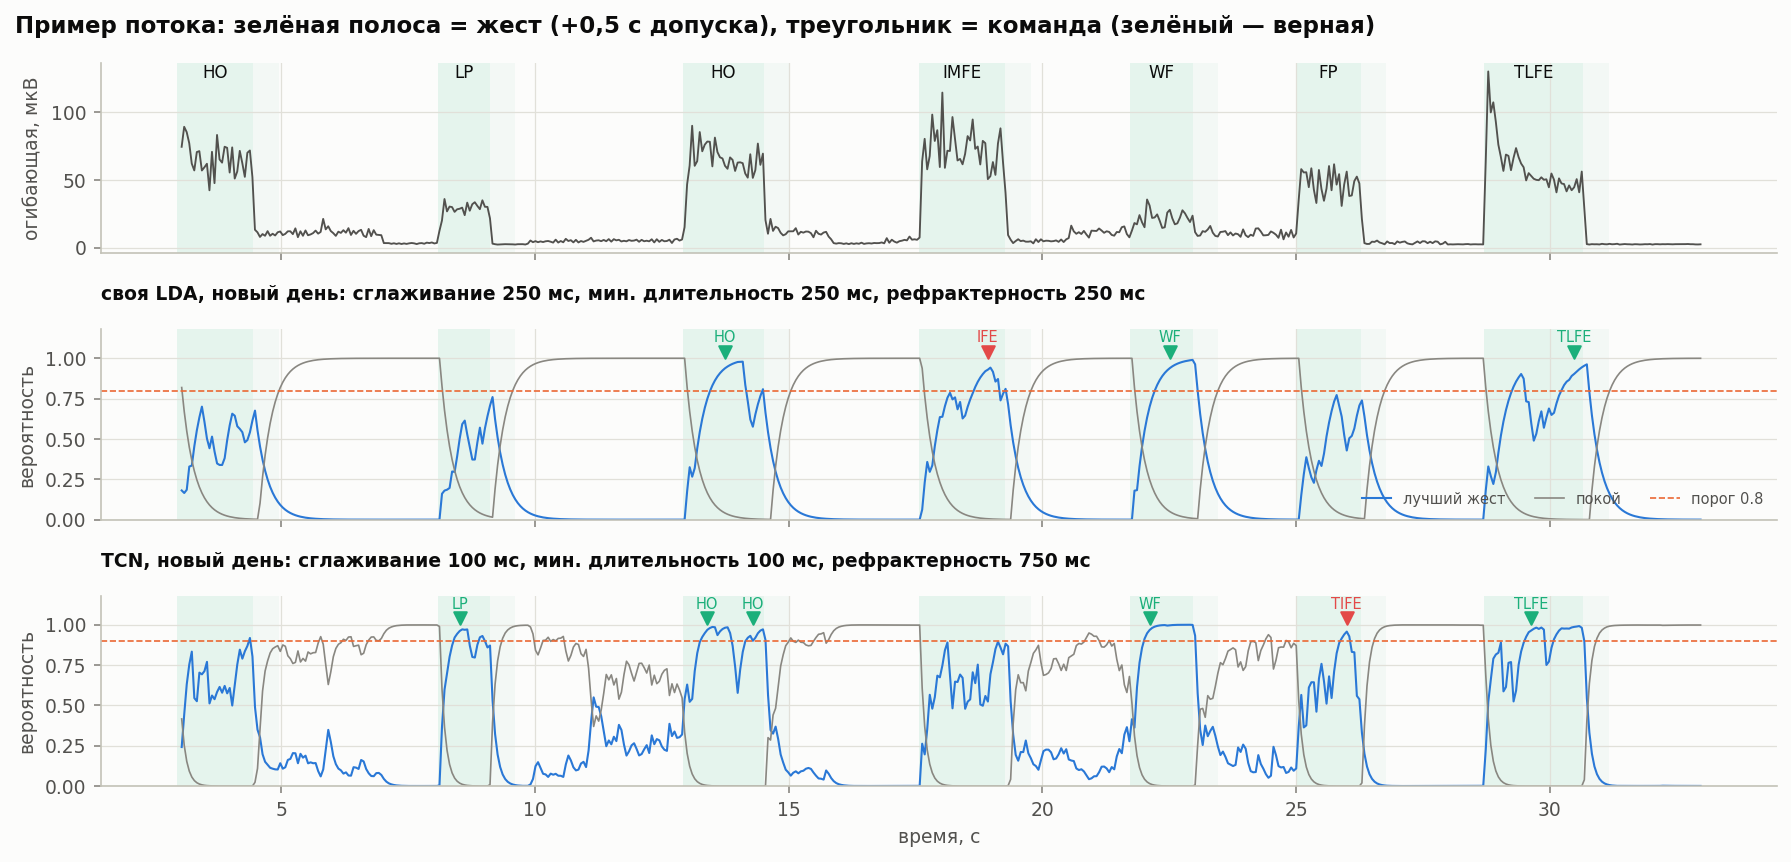

In [2]:
cfg = yaml.safe_load((ROOT / "configs" / "stream_dev.yaml").read_text(encoding="utf-8"))
res_dev = load("stream_dev")
cache = run.stream_cache_path(cfg)
if res_dev and cache.exists():
    probs, truths, _ = pickle.loads(cache.read_bytes())          # model probabilities, computed by run.py
    p, s, sc, pre = 11, 2, cfg["stream"], cfg["preprocess"]
    st = streaming.build_stream(p, s, sc["trials"], cfg["seed"], tuple(sc["gesture_s"]), tuple(sc["rest_s"]),
                                sc["lead_s"], sc["rise_ms"], sc["fall_ms"], sc["join_ms"])
    sos = design_filter(band_hz=tuple(pre["band_hz"]), order=pre["order"], notch_hz=tuple(pre["notch_hz"]))
    x_filt, _ = filter_causal(st.x, sos)
    ops = pd.DataFrame(res_dev["operating_points"]).set_index(["model", "experiment"])
    models = {}
    for m in ["lda", "tcn"]:
        o = ops.loc[(m, "E2")]
        t, P, classes, _, _ = probs[(m, "E2", p, s)]
        Ps = streaming.smooth(P, cfg["windows"]["step_ms"] / 1000, o.tau_ms)
        events = streaming.detect(Ps, t, o.theta, o.min_ms, o.refractory_ms, classes)
        label = (f"{NAMES[(m, 'E2')]}: сглаживание {o.tau_ms:g} мс, мин. длительность {o.min_ms:g} мс, "
                 f"рефрактерность {o.refractory_ms:g} мс")
        models[label] = (t, Ps, classes, o.theta, events)
    display(Image(streaming.plot_stream_example(st, x_filt, models, 3, 33, f"p{p}_s{s}", sc["tol_ms"] / 1000)))
elif res_dev:
    print("Нет кэша вероятностей: сначала python run.py --config configs/stream_dev.yaml")

**Как читать:** верхняя панель — средняя по 12 каналам огибающая сигнала (RMS за 50 мс), зелёные полосы — жесты
(светлая часть — допуск 0,5 с). Ниже для каждой модели — сглаженная вероятность самого вероятного жеста (синяя),
покоя (серая) и порог (пунктир); треугольники — команды: зелёные верные, красные — неверного класса или вне жеста.

**Что видно на этих 30 секундах** (одна сессия, не обобщение):
- **LDA** в паузах уверенно видит покой (серая линия у 1), ложных нет. Но внутри жестов вероятность жеста часто
  не доходит до порога 0,8: пропущены HO, LP, FP; IMFE перепутан с IFE (оба — разгибание пальцев).
- **TCN** внутри жестов быстро и уверенно выходит за порог 0,9. В паузах её покой «проседает» до 0,6–0,8
  (например, 10–12 с), но вероятность жеста остаётся ниже порога — ложных нет. Один лишний HO (дрожание внутри жеста),
  FP перепутан с TIFE, первые HO и IMFE пропущены.

## 3. Постобработка: от вероятностей к командам

Четыре «ручки», у каждой своя польза и цена:

| ручка | что делает | цена |
|---|---|---|
| **сглаживание** τ: $\bar p_t = a\,p_t + (1-a)\,\bar p_{t-1}$, $a = 1 - e^{-50\,\text{мс}/\tau}$ | гасит одиночные выбросы | задержка: с порогом 0,9 и τ = 100 мс — ~300 мс |
| **порог** θ | команда-кандидат, если вероятность лучшего жеста (не покоя) ≥ θ | высокий: меньше ложных, больше пропусков и задержка |
| **минимальная длительность** | жест должен продержаться выше порога столько времени | + её длительность к задержке |
| **рефрактерный период** | новая команда — только после спада **всех** жестов ниже порога и не раньше чем через T_ref | быстрые повторы одного жеста склеиваются |

Один удержанный жест даёт одну команду, дрожание около порога — тоже одну. Перебор на dev: τ ∈ {0, 100, 250} мс,
минимальная длительность ∈ {0, 100, 250} мс, рефрактерность ∈ {250, 750} мс, 10 порогов от 0,3 до 0,98 — 180 сочетаний.

## 4. Метрики событий

Каждому жесту принадлежит интервал **[начало разгона, конец затухания + 0,5 с)**; допуск 0,5 с — на запаздывание
решения (окно 200 мс, сглаживание, минимальная длительность).

| событие | что это |
|---|---|
| первое событие в интервале жеста | решает исход: класс совпал — **верно**, нет — **перепутано**; событий нет — **пропуск** |
| следующие события в том же интервале | **лишние** (повторные команды на один жест) |
| вне всех интервалов, после 3 с прогрева | **ложное срабатывание** |

Метрики потока: доли верных / перепутанных / пропусков (в сумме 1), лишние на жест, **ложные в минуту покоя**
(покой = поток без интервалов жестов), **задержка** — медиана «верная команда − начало жеста». Дальше — среднее по
потокам участника, затем по участникам.

**Рабочая точка** — сочетание ручек с наибольшей долей верных команд при **≤ 1 ложном срабатывании в минуту покоя
и ≤ 0,1 лишней команды на жест** (средние по участникам); выбирается на dev для каждой модели и сценария и
замораживается для test. Ограничение на лишние добавлено после первого разбора: без него у TCN в новый день
выбиралась быстрая настройка, дававшая 1,65 команды на жест, а лишняя команда для пользователя — такое же
нежелательное нажатие, как ложная.

## 5. Результаты на dev (10 участников)

finished 2026-10-28T14:14:46 | потоков 30 | минут в потоке 4.76 | уникального покоя, с 19.9


,"сглаж. / мин. длит. / рефракт., мс; порог","верные, %","перепутанные, %","пропуски, %",лишние на жест,ложные в мин: среднее (медиана) [макс],"задержка, мс"
"своя LDA, новый день",250 / 250 / 250; 0.8,70.3 ± 13.3,7.9 ± 5.5,21.8 ± 9.4,0.03,0.88 (0.00) [6.6],775.1 ± 18.0
"своя LDA, новый человек",250 / 0 / 750; 0.85,74.4 ± 9.3,9.4 ± 4.9,16.2 ± 5.9,0.05,0.96 (0.00) [6.0],594.8 ± 7.2
"TCN, новый день",100 / 100 / 750; 0.9,83.9 ± 6.5,3.6 ± 2.3,12.5 ± 5.2,0.09,0.49 (0.00) [4.2],421.8 ± 11.9
"TCN, новый человек",250 / 100 / 750; 0.5,86.2 ± 2.0,12.1 ± 2.5,1.7 ± 1.1,0.07,0.90 (0.00) [5.4],378.4 ± 9.4


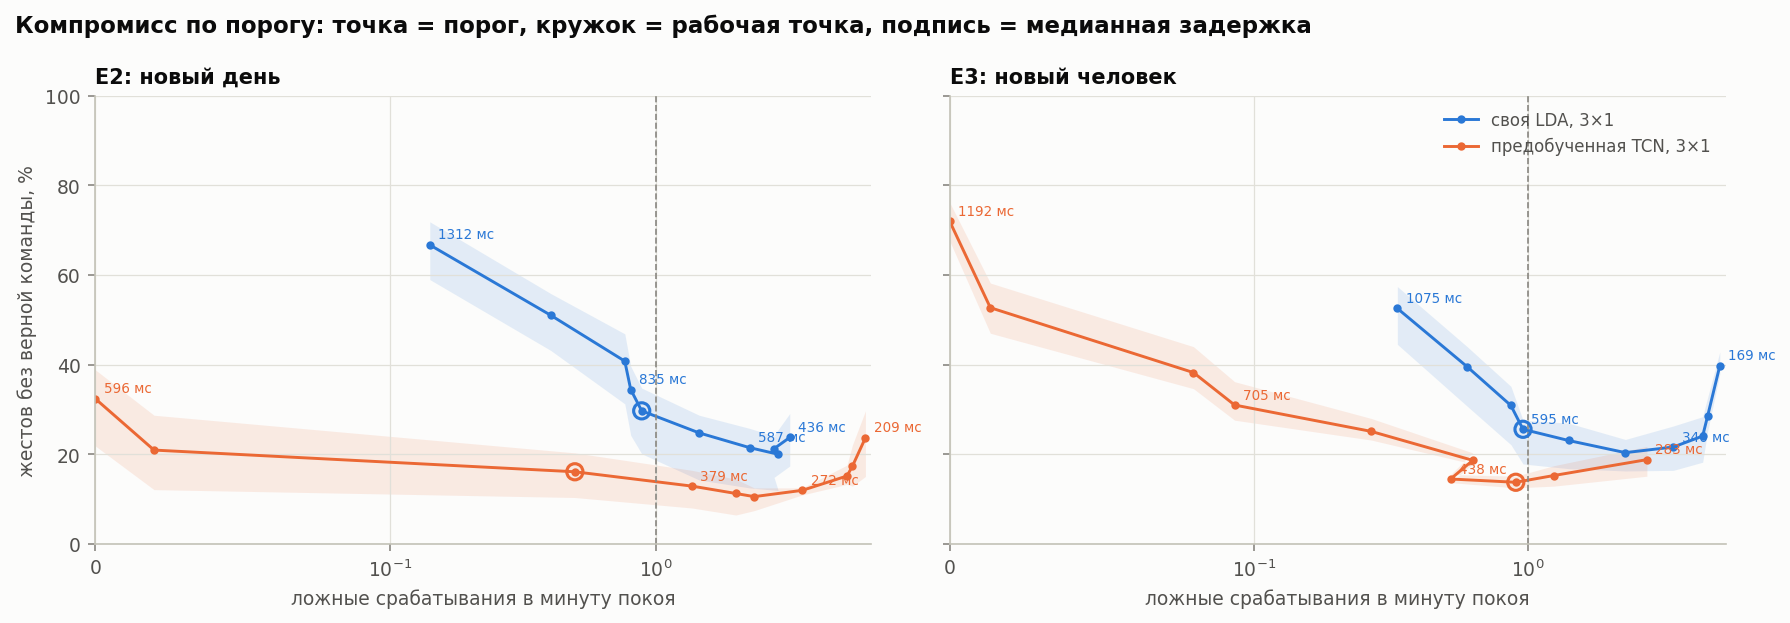

In [3]:
if res_dev:
    print("finished", res_dev["finished"], "| потоков", res_dev["n_streams"],
          "| минут в потоке", res_dev["stream_minutes_mean"], "| уникального покоя, с", res_dev["unique_rest_s_per_session"])
    display(point_table(res_dev))
    for f in res_dev["figures"]:
        display(Image(ROOT / f))

**Как читать график:** по оси X — ложные срабатывания в минуту покоя (пунктир — 1 в минуту), по оси Y — доля жестов без
верной команды; точки — пороги при выбранных остальных ручках, кружок — рабочая точка, подписи — медианная задержка.
Чем ниже и левее кривая, тем лучше.

1. **TCN с калибровкой 51 с работает в потоке:** 84–86 % жестов дают верную команду, лишних почти нет, задержка
   ~380–420 мс — на 80–120 мс больше ориентира ~300 мс, это цена защиты от лишних команд.
2. **LDA на 12–14 п.п. хуже и в 1,5–2 раза медленнее** (600–775 мс): ей нужны высокий порог и сильное сглаживание,
   отсюда пропуски (16–22 %) и задержка.
3. **Разрыв между моделями в событиях больше, чем в окнах** (окна, этап 5: 86 / 77 % в новый день; команды: 84 / 70 %).
   Первая гипотеза — «ошибки LDA в покое идут длинными сериями» — пример выше не подтверждает: у большинства участников
   покой LDA чистый. Вероятнее другое: **порог общий для всех, а ограничение на среднее число ложных задают
   2 участника** (38 и 40, до 6,6 в минуту). Чтобы их «утихомирить», порог LDA поднят до 0,80–0,85, и у остальных он
   превращается в пропуски: внутри жестов LDA менее уверена, чем сеть.
4. **Ложные срабатывания сосредоточены в 2–6 сессиях из 20–30**: медиана 0, среднее определяют 2 участника.

## 6. Итог на test (5 участников, один прогон)

finished 2026-10-28T14:17:30 | потоков 15


,"сглаж. / мин. длит. / рефракт., мс; порог","верные, %","перепутанные, %","пропуски, %",лишние на жест,ложные в мин: среднее (медиана) [макс],"задержка, мс"
"своя LDA, новый день",250 / 250 / 250; 0.8,61.9 ± 14.9,7.2 ± 5.0,30.9 ± 12.6,0.04,1.13 (0.00) [5.6],788.1 ± 13.5
"своя LDA, новый человек",250 / 0 / 750; 0.85,67.3 ± 15.9,11.1 ± 5.3,21.6 ± 12.9,0.04,2.17 (0.00) [6.1],624.8 ± 64.5
"TCN, новый день",100 / 100 / 750; 0.9,77.8 ± 10.3,4.5 ± 5.3,17.7 ± 10.9,0.12,1.71 (0.00) [7.5],432.0 ± 27.0
"TCN, новый человек",250 / 100 / 750; 0.5,89.5 ± 7.4,8.6 ± 5.9,1.9 ± 2.0,0.07,0.86 (0.26) [2.8],378.0 ± 10.4


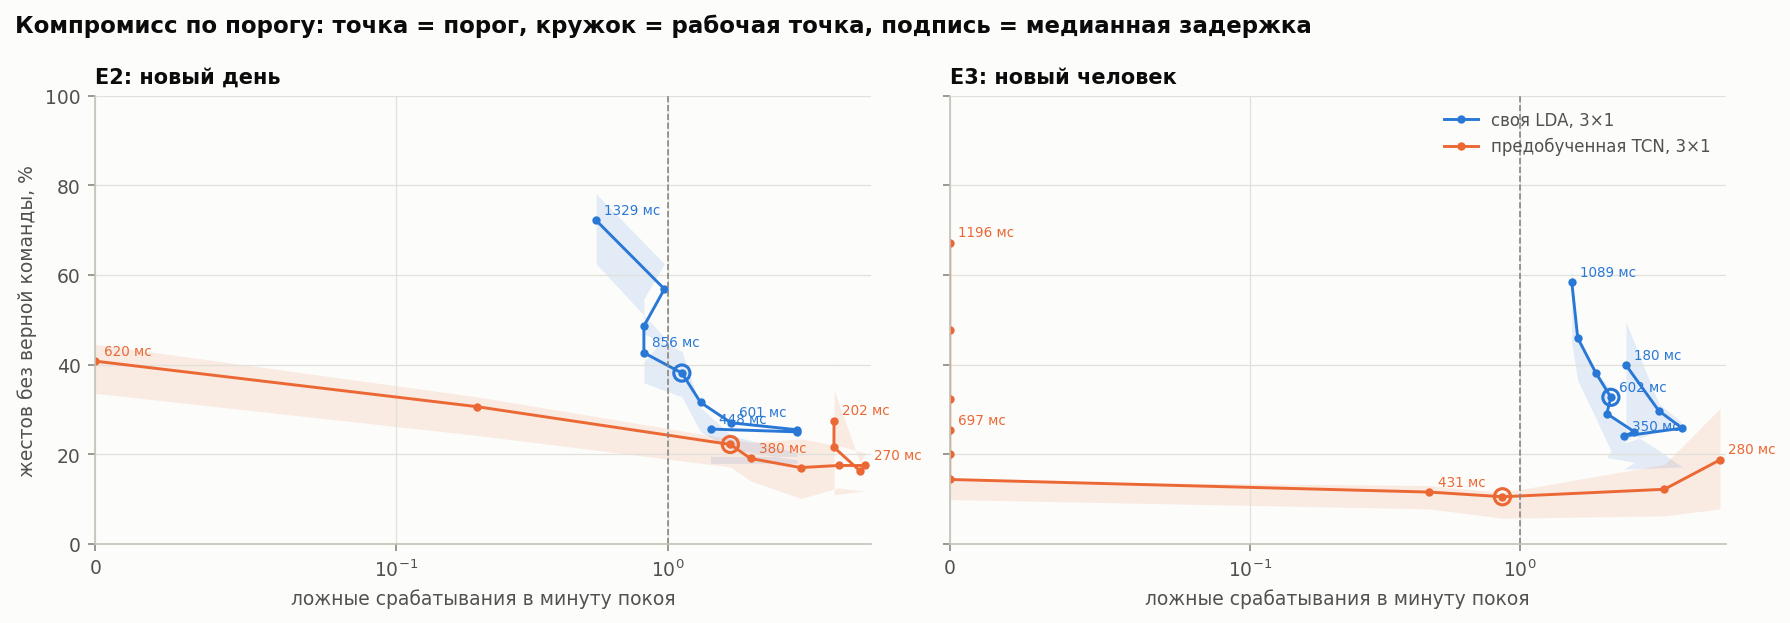

,"верные, dev","верные, test","ложные/мин, dev","ложные/мин, test","точность по окнам, test (этап 5)"
"своя LDA, новый день",70.3,61.9,0.88,1.13,72.6
"своя LDA, новый человек",74.4,67.3,0.96,2.17,72.6
"TCN, новый день",83.9,77.8,0.49,1.71,82.0
"TCN, новый человек",86.2,89.5,0.90,0.86,83.6


In [4]:
res_test = load("stream_test")
if res_test:
    print("finished", res_test["finished"], "| потоков", res_test["n_streams"])
    display(point_table(res_test))
    for f in res_test["figures"]:
        display(Image(ROOT / f))

    # dev vs test, and windows (stage 5, calibration 3x1) vs events
    win = {}
    for name, model, method in [("adapt_tcn_test", "tcn", "full"), ("adapt_lda_test", "lda", "scratch")]:
        pp = pd.DataFrame(load(name)["per_participant"])
        for e, v in pp[(pp.method == method) & (pp.budget == "3x1")].groupby("experiment").bal_acc.mean().items():
            win[(model, e)] = 100 * v
    rows = {}
    for key in NAMES:
        d = pd.DataFrame(res_dev["operating_points"]).set_index(["model", "experiment"]).loc[key]
        t_ = pd.DataFrame(res_test["operating_points"]).set_index(["model", "experiment"]).loc[key]
        rows[NAMES[key]] = {"верные, dev": round(100 * d.correct, 1), "верные, test": round(100 * t_.correct, 1),
                            "ложные/мин, dev": round(d.fa_per_min, 2), "ложные/мин, test": round(t_.fa_per_min, 2),
                            "точность по окнам, test (этап 5)": round(win[key], 1)}
    display(pd.DataFrame(rows).T)

1. **Лучший результат этапа — TCN для нового человека:** 89,5 % верных команд, 0,86 ложных в минуту, 378 мс;
   перенеслось с dev без потерь, у всех 5 участников ≥ 77 %.
2. **TCN в новый день на test слабее:** 77,8 % верных и 1,7 ложных в минуту — ограничение не выполнено из-за 1–2 сессий
   (участник 19 — 7,5 ложных в минуту, участник 5 — 37 % пропусков); медиана ложных 0.
3. **LDA хуже TCN у всех 5 участников** в обоих сценариях (+16 / +22 п.п. верных у TCN, задержка меньше на 250–360 мс).
4. **Ограничение на ложные, подобранное на dev, на test держится только у TCN для нового человека.** Ложные срабатывания —
   редкие события, сосредоточенные в нескольких сессиях; 20 с уникального покоя на сессию для их оценки мало.
5. Модель на 10 людях (новый человек) в потоке устойчивее модели на своей сессии 1 (новый день): 89,5 против 77,8 %
   (сравнение не строго попарное: разные наборы сессий) — как на этапах 4–5.

## 7. Выводы этапа 6

| test, рабочая точка | верные команды | ложные в минуту | лишние на жест | задержка |
|---|---|---|---|---|
| **TCN, новый человек** | **89,5 %** | 0,86 | 0,07 | 378 мс |
| TCN, новый день | 77,8 % | 1,71 | 0,12 | 432 мс |
| своя LDA, новый человек / новый день | 67,3 / 61,9 % | 2,17 / 1,13 | 0,04 | 625 / 788 мс |

1. **Для потокового управления подходит только предобученная TCN с короткой калибровкой**; LDA теряет и в доле верных
   команд, и в скорости.
2. **Постобработка — это выбор продукта:** сглаживание и высокий порог убирают ложные и лишние команды, но стоят
   задержки; рефрактерный период задержку первой команды не меняет.
3. **Главное ограничение — оценка ложных срабатываний.** По «правилу трёх» при нуле ложных за N минут можно утверждать
   лишь ≤ 3 / N в минуту: 5 минут уникального покоя на test дают ≤ 0,6 в минуту, а для уровня продукта (≤ 1 в час)
   нужны часы записи. Кроме того, опасен не покой на столе, а повседневные движения, похожие на жесты, — их в GRABMyo нет.

**Ограничения:** поток склеен из попыток (разгон и затухание 50 мс — допущение, задержка — нижняя оценка); покой
повторяется; жесты короткие и сбалансированные; схема «нажатие» (удержание и отпускание не оценивались); один сид.

**Что бы улучшить:** гистерезис (высокий порог для срабатывания, низкий — для отпускания) вместо сильного сглаживания;
собственные длинные записи повседневной активности с отмеченными жестами для оценки ложных срабатываний в час.

## Открытые вопросы
1. **Почему разрыв между моделями в событиях больше, чем в окнах** (новый день, test: окна 82 против 73 %, команды
   78 против 62 %)? Гипотеза — порог общий для всех, а ограничение на среднее число ложных задают 2 участника; ради них
   порог LDA поднят, и у остальных он превращается в пропуски. Длину серий ошибок напрямую не считали.
2. **Можно ли защититься от лишних команд без задержки?** Сглаживание и высокий порог подняли задержку TCN с 237 до
   422 мс; рефрактерный период задержку первой команды не меняет. Гистерезис (высокий порог для срабатывания,
   низкий — для отпускания) не проверялся.
3. **Как оценить частоту ложных срабатываний на уровне продукта** (≤ 1 в час)? Нужны часы непрерывного ношения
   с повседневной активностью и отмеченными жестами (кнопка или видео), несколько надеваний и дней — в GRABMyo
   таких записей нет.